# Geometric coordinates to degree conversion for saccades

In [ ]:
BASE_FOLDER = '/home/asyeda/stringerlab_dm11/eye-vs-face/' # set path parent folder called eye-vs-facce which should contain 'data' folder

In [ ]:
import matplotlib.pyplot as plt
import os, sys
sys.path.append(os.path.join(BASE_FOLDER, 'analysis/code'))
import nonlinear_modelv3
import helper_functions
import numpy as np
import pupil_dark_helpers as pdh

In [2]:
def eudist(x, y):
    d = ((x[0]-y[0])**2 + (x[1]-y[1])**2)**.5
    return d

def polar_coo(xy, c1, c2):
    # xy are coordinates of the pupil
    # c1 is the left corner (XY coord)
    # c2 is the right corner (XY coord)
    c00 = (np.array(c1) + np.array(c2)) / 2
    arot = np.array([[0, 1], [-1, 0]])
    c3 = c00 + arot @ (np.array(c2) - c00)

    beta_x = get_angle(xy, c1, c00)
    beta_y = get_angle(xy, c3, c00)

    return beta_x, beta_y

def get_angle(xy, c1, c00):
    b = eudist(xy, c1)
    a = eudist(xy, c00)
    R = eudist(c1, c00)
    d = (R**2 - a**2 + b**2)**.5
    beta = np.pi - 2 * np.arccos(d/(2*R))
    return beta

## Load recordings

In [ ]:
dbs = pdh.get_light_static_info()
mouse_list = np.unique([entry['mname'] for entry in dbs])
mouse_list

Sessions from get_light_static_info >>>


In [ ]:
mname = 'FXa10' # example mouse to test loading data and processing
datexp = [entry['datexp'] for entry in dbs if entry['mname'] == mname][0]
axis_info = None

In [ ]:
if mname in ['FXa10', 'FXa8', 'FXa9', 'FXa1']:
    axis_file = os.path.join(BASE_FOLDER, "data", "mouse_data", mname, datexp, "1", "{}_{}_eyekp.npy".format(mname, datexp)) 
else:
    axis_file = os.path.join(BASE_FOLDER, "data", "mouse_data", mname, datexp, "{}_{}_eyekp.npy".format(mname, datexp)) 
axis_info = np.load(axis_file, allow_pickle=True).item()
if axis_info is not None:
    c1 = axis_info['c1']
    c2 = axis_info['c2']
    print(c1, c2)

(2, 49) (141, 44)


In [ ]:
_, _, _, tcams, tneurals, _, _, npz_data = nonlinear_modelv3.load_data(f"{BASE_FOLDER}data/npz_data/", mname, datexp)

In [8]:
pupil_x = npz_data['pupil_x_small']
pupil_y = npz_data['pupil_y_small']
blink = npz_data['blink_small']

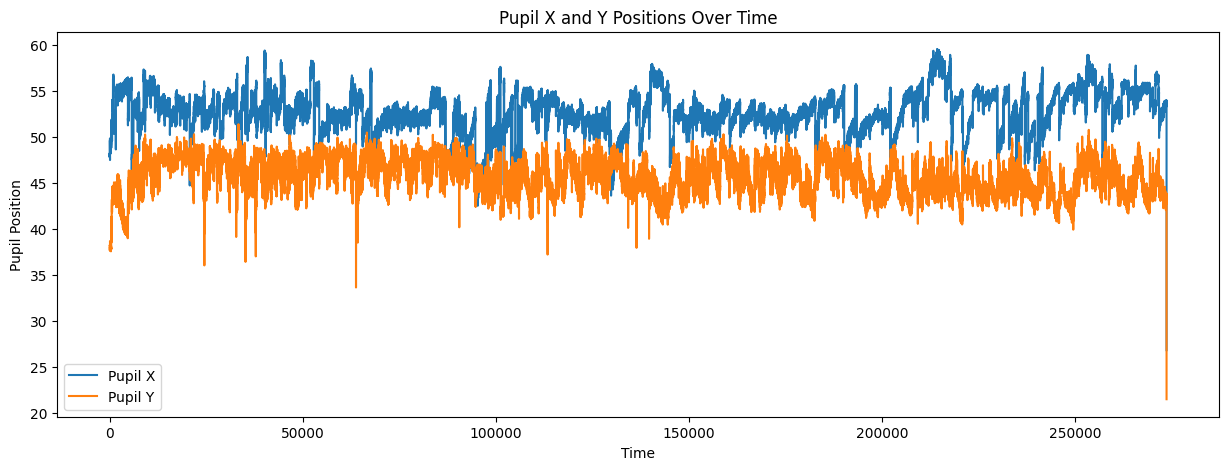

In [9]:
# Plot pupil x and y
plt.figure(figsize=(15, 5))
plt.plot(pupil_x, label='Pupil X')
plt.plot(pupil_y, label='Pupil Y')
plt.xlabel('Time')
plt.ylabel('Pupil Position')
plt.title('Pupil X and Y Positions Over Time')
plt.legend()
plt.show()

In [ ]:
video_path = f"{BASE_FOLDER}data/cam_data/{mname}_{datexp}_{1}_small.mp4"
print(video_path)
frames, _ = helper_functions.load_video_frames(video_path)
vid_width, vid_height = frames.shape[-1], frames.shape[-2]
print(vid_width, vid_height)

/home/asyeda/nas113/Atika/FXa10/2026_01_13/1//FXa10_2026_01_13_1_small.mp4
132 88


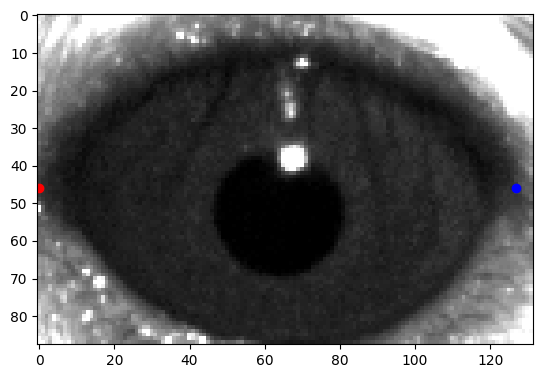

In [11]:
frame_idx = np.random.randint(0, len(frames))
plt.imshow(frames[frame_idx], cmap='gray', vmin=0, vmax=90)
if axis_info is not None:
    c1 = axis_info['c1']
    c2 = axis_info['c2']
else:
    c1 = (2, 49)
    c2 = (141, 44)
plt.scatter(c1[0], c1[1], color='red')
plt.scatter(c2[0], c2[1], color='blue')

In [ ]:
# save c1, c2 for later use
if mname in ["FXa1", "FXa8", "FXa9", "FXa10"]:
    np.save(f"{BASE_FOLDER}/{mname}/{datexp}/1/{mname}_{datexp}_eyekp.npy", {'c1': c1, 'c2': c2})
else:
    np.save(f"{BASE_FOLDER}/{mname}/{datexp}/{mname}_{datexp}_eyekp.npy", {'c1': c1, 'c2': c2})

In [10]:
xy = np.array([pupil_x, pupil_y]).T
beta_x, beta_y = [], []
for i in range(0, len(xy)):
    x = xy[i]
    bx, by = polar_coo(x, c1, c2)
    # convert to degrees
    bx = np.degrees(bx)
    by = np.degrees(by)
    beta_x.append(bx)
    beta_y.append(by)

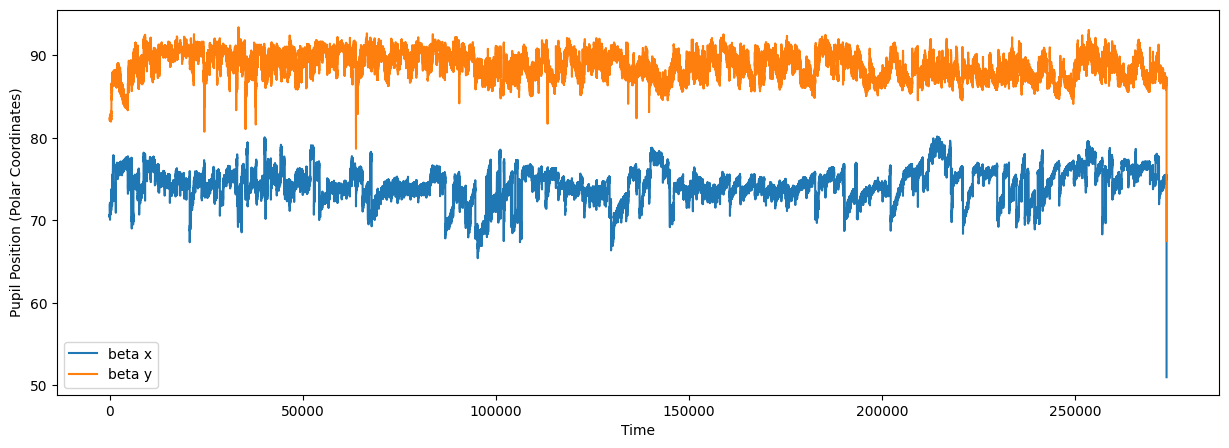

In [11]:
# Plot pupil x and y
plt.figure(figsize=(15, 5))
plt.plot(beta_x, label='beta x')
plt.plot(beta_y, label='beta y')
plt.xlabel('Time')
plt.ylabel('Pupil Position (Polar Coordinates)')
plt.legend()
plt.show()

In [12]:
# Save the polar coordinates and axis info: c1, c2
existing_data = dict(npz_data)
existing_data['pupil_x_polar'] = np.array(beta_x)
existing_data['pupil_y_polar'] = np.array(beta_y)
existing_data['axis_info'] = np.array([c1, c2])
print(existing_data['pupil_x_polar'].shape, existing_data['pupil_y_polar'].shape, existing_data['pupil_x_small'].shape)

(273631,) (273631,) (273631,)


In [ ]:
# Save the polar coordinates and axis info: c1, c2
if mname in ["FXa1", "FXa8", "FXa9", "FXa10"]:
    np.savez(f"{BASE_FOLDER}/{mname}/{datexp}/1/{mname}_{datexp}_{1}.npz", **existing_data)
    print(f"Saved polar coordinates and axis info to {BASE_FOLDER}/{mname}/{datexp}/1/{mname}_{datexp}_{1}.npz")
else:
    np.savez(f"{BASE_FOLDER}/{mname}/{datexp}/{mname}_{datexp}_{1}.npz", **existing_data)
    print(f"Saved polar coordinates and axis info to {BASE_FOLDER}/{mname}/{datexp}/{mname}_{datexp}_{1}.npz")

Saved polar coordinates and axis info to /home/asyeda/nas113/Atika/FXa10/2026_01_16/1//FXa10_2026_01_16_1.npz
